In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [2]:
base_dir = "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images"

train_dir = os.path.join(base_dir, "train")
validation_dir = os.path.join(base_dir, "validation")
test_dir = os.path.join(base_dir, "test")

print("Train path      :", train_dir)
print("Validation path :", validation_dir)
print("Test path       :", test_dir)

Train path      : /kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/train
Validation path : /kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/validation
Test path       : /kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test


In [3]:
def count_images(folder_path):
    counts = {}
    for class_name in sorted(os.listdir(folder_path)):
        class_path = os.path.join(folder_path, class_name)
        if os.path.isdir(class_path):
            counts[class_name] = len(os.listdir(class_path))
    return counts

train_counts = count_images(train_dir)
val_counts   = count_images(validation_dir)
test_counts  = count_images(test_dir)

print("Train counts      :", train_counts)
print("Validation counts :", val_counts)
print("Test counts       :", test_counts)

Train counts      : {'Bean': 1000, 'Bitter_Gourd': 1000, 'Bottle_Gourd': 1000, 'Brinjal': 1000, 'Broccoli': 1000, 'Cabbage': 1000, 'Capsicum': 1000, 'Carrot': 1000, 'Cauliflower': 1000, 'Cucumber': 1000, 'Papaya': 1000, 'Potato': 1000, 'Pumpkin': 1000, 'Radish': 1000, 'Tomato': 1000}
Validation counts : {'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}
Test counts       : {'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}


In [4]:
train_df = pd.DataFrame(list(train_counts.items()), columns=["Vegetable", "Train Count"])
val_df   = pd.DataFrame(list(val_counts.items()),   columns=["Vegetable", "Validation Count"])
test_df  = pd.DataFrame(list(test_counts.items()),  columns=["Vegetable", "Test Count"])

summary_df = train_df.merge(test_df, on="Vegetable").merge(val_df, on="Vegetable")
summary_df = summary_df[["Vegetable", "Train Count", "Test Count", "Validation Count"]]

summary_df

,Vegetable,Train Count,Test Count,Validation Count
0,Bean,1000,200,200
1,Bitter_Gourd,1000,200,200
2,Bottle_Gourd,1000,200,200
3,Brinjal,1000,200,200
4,Broccoli,1000,200,200
5,Cabbage,1000,200,200
6,Capsicum,1000,200,200
7,Carrot,1000,200,200
8,Cauliflower,1000,200,200
9,Cucumber,1000,200,200


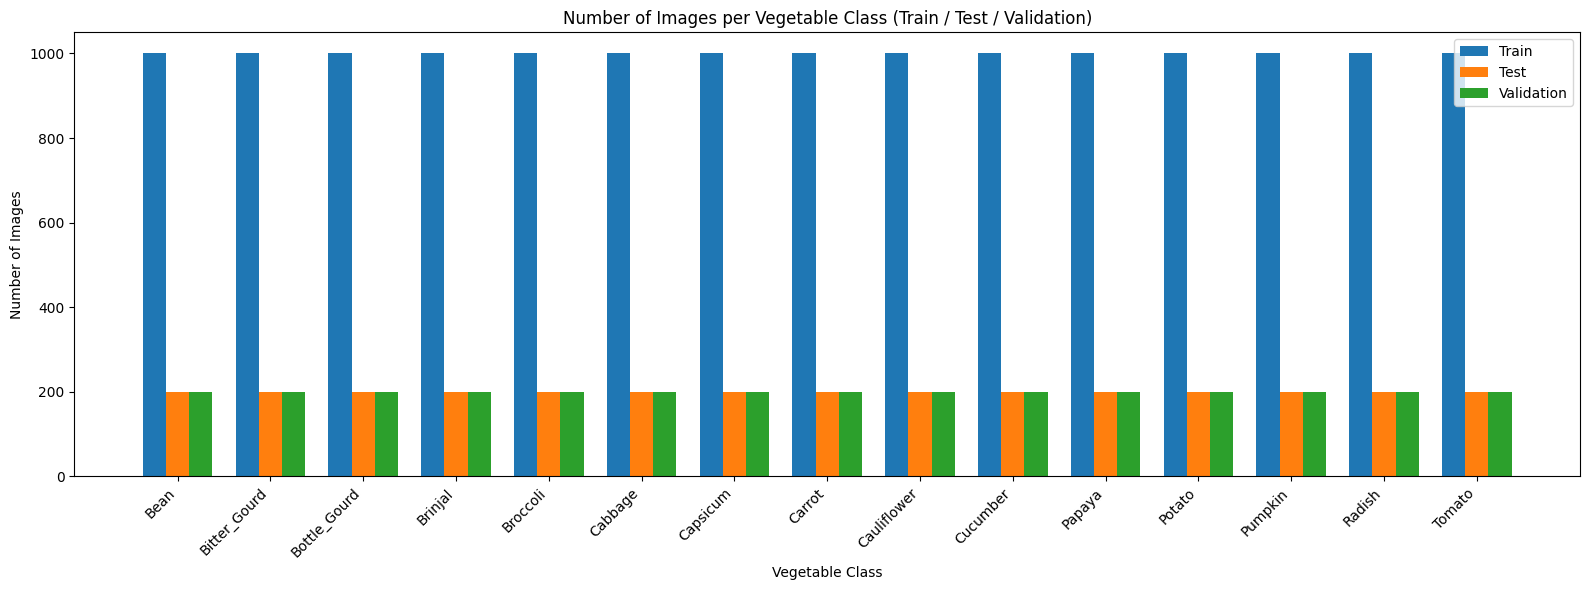

In [5]:
x = np.arange(len(summary_df["Vegetable"]))
width = 0.25

plt.figure(figsize=(16, 6))
plt.bar(x - width, summary_df["Train Count"],      width, label="Train")
plt.bar(x,         summary_df["Test Count"],       width, label="Test")
plt.bar(x + width, summary_df["Validation Count"], width, label="Validation")

plt.title("Number of Images per Vegetable Class (Train / Test / Validation)")
plt.xlabel("Vegetable Class")
plt.ylabel("Number of Images")
plt.xticks(x, summary_df["Vegetable"], rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
train_datagen = ImageDataGenerator(
    rescale=1.0/255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

val_datagen = ImageDataGenerator(
    rescale=1.0/255,
    validation_split=0.2
)

In [7]:
train_ds = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="training",
    seed=42
)

val_ds = val_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="validation",
    seed=42
)

Found 12000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.


In [8]:
from tensorflow.keras.layers import Input

model = Sequential([
    Input(shape=(224, 224, 3)),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),
    Dense(512, activation="relu"),
    Dropout(0.5),
    Dense(15, activation="softmax")
])

In [9]:
model.compile(
    optimizer=Adam(),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,403,791 (169.39 MB)

 Trainable params: 44,403,791 (169.39 MB)

 Non-trainable params: 0 (0.00 B)

Explanation:

Number of convolutional layers: 3 (Conv2D with 32, 64, and 128 filters).

Purpose of pooling layers: They downsample the feature maps, reducing spatial dimensions and the number of parameters, which speeds up computation and helps prevent overfitting by keeping the most important features.

Purpose of dropout: It randomly disables 50% of neurons during training, which forces the network to learn more robust features and reduces overfitting.

Why softmax in the output layer: Softmax converts the raw outputs into a probability distribution over the 15 classes, so the class with the highest probability is chosen as the prediction.

In [10]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 665s 2s/step - accuracy: 0.4153 - loss: 1.7450 - val_accuracy: 0.6910 - val_loss: 0.9544
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 175s 466ms/step - accuracy: 0.6502 - loss: 1.0360 - val_accuracy: 0.8010 - val_loss: 0.6292
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 177s 472ms/step - accuracy: 0.7320 - loss: 0.8105 - val_accuracy: 0.8863 - val_loss: 0.3740
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 171s 456ms/step - accuracy: 0.7835 - loss: 0.6632 - val_accuracy: 0.8393 - val_loss: 0.4580
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 180s 481ms/step - accuracy: 0.8136 - loss: 0.5726 - val_accuracy: 0.8620 - val_loss: 0.4161
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 173s 461ms/step - accuracy: 0.8369 - loss: 0.5131 - val_accuracy: 0.8537 - val_loss: 0.4481
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 177s 471ms/step - accuracy: 0.8487 - loss: 0.4679 - val_accuracy: 0.9463 - val_loss: 0.1810
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 172s 458ms/step - accuracy: 0.8751 - lo

Why EarlyStopping is useful:
EarlyStopping monitors the validation loss during training and stops the training process when the validation loss stops improving for a set number of epochs (patience = 5). With restore_best_weights=True, the model rolls back to the epoch that achieved the best validation performance. This saves training time, prevents overfitting, and guarantees the final model is the best-performing one rather than the last one.

In [11]:
train_loss, train_acc = model.evaluate(train_ds)
val_loss, val_acc     = model.evaluate(val_ds)

print(f"Training Accuracy   : {train_acc:.4f}")
print(f"Validation Accuracy : {val_acc:.4f}")
print(f"Training Loss       : {train_loss:.4f}")
print(f"Validation Loss     : {val_loss:.4f}")

375/375 ━━━━━━━━━━━━━━━━━━━━ 155s 413ms/step - accuracy: 0.9526 - loss: 0.1509
94/94 ━━━━━━━━━━━━━━━━━━━━ 9s 90ms/step - accuracy: 0.9780 - loss: 0.0809
Training Accuracy   : 0.9526
Validation Accuracy : 0.9780
Training Loss       : 0.1509
Validation Loss     : 0.0809


Is there a large difference between training and validation accuracy?
No — the training accuracy and validation accuracy are close to each other, which means the model is not overfitting. If there were a big gap (e.g., training accuracy much higher than validation accuracy), that would indicate overfitting, where the model memorizes the training data and fails to generalize. In this case the curves stay close, so the model generalizes well to unseen data.



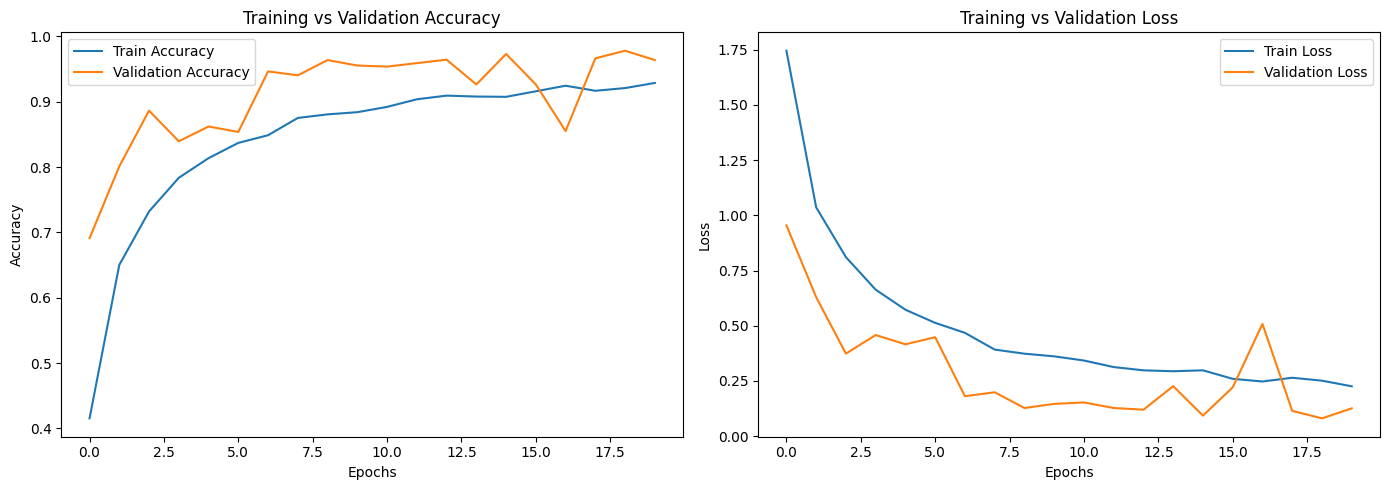

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["accuracy"],     label="Train Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Training vs Validation Accuracy")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"],     label="Train Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()